In [1]:
from transformers import pipeline, AutoModelForCausalLM, AutoTokenizer
import torch, gc, time


In [5]:
def free_gpu(model):
    if model:
        del model
    if torch.cuda.is_available:
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    gc.collect()

In [6]:
model_path = "/srv/models/qwen2.5-0.5B"

In [7]:
tokenizer = AutoTokenizer.from_pretrained(model_path, trust_remote_code=True)

Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


In [8]:
model = (
    AutoModelForCausalLM.from_pretrained(model_path, trust_remote_code=True).to("cuda" if torch.cuda.is_available else "cpu")
)

In [9]:
# prompt = "The history of human … … … How might the next wave of communication tools shape our relationships, societies, and sense of identity?"
prompt = "United States citizens have a bunch of benefits like"

In [10]:
max_new_tokens = 100

In [11]:
idx = tokenizer(prompt, return_tensors="pt").input_ids.to(model.device)
print(idx)

tensor([[22372,  4180, 10283,   614,   264, 15493,   315,  7567,  1075]],
       device='cuda:0')


In [12]:
start_time = total_time = time.time()

1795426356.7554917


In [13]:
times = []

In [14]:
for i in range(max_new_tokens):
    idx_cond = idx
    with torch.no_grad():
        # get predictions (token candidates)
        outputs = model(idx_cond)
        # print("outputs: ", outputs)
        # get prediction scores
        logits = outputs.logits
        # print("logits: ", logits)
    # get only logits for the last token
    logits = logits[:, -1, :]
    # print("logits (last token): ", logits)
    # get probability distribution
    probas = torch.softmax(logits, dim=-1)
    # print("probas: ", probas)
    # get the next token
    idx_next = torch.multinomial(probas, num_samples=1)
    # print("idx_next: ", idx_next)
    # print("Next token is: ", tokenizer.decode(idx_next[0]))
    time_cost = time.time() - start_time
    times.append(time_cost)
    if not i:
        print(f"Time taken to generate first token is: {time_cost:.4f} seconds")
    else:
        print(f"Time taken to generate {i} token is: {time_cost:.4f} seconds")
        
    start_time = time.time()
    idx = torch.cat((idx, idx_next), dim=1)
    # EOS - End Of Sequence
    if idx_next.item() == tokenizer.eos_token_id:
        print("\n[Generation completed - EOS token has been generated]")
        break
print(f"Total generation time is {time.time() - total_time:.4f} seconds")

Time taken to generate first token is: 0.1515 seconds
Time taken to generate 1 token is: 0.0222 seconds
Time taken to generate 2 token is: 0.0223 seconds
Time taken to generate 3 token is: 0.0239 seconds
Time taken to generate 4 token is: 0.0217 seconds
Time taken to generate 5 token is: 0.0217 seconds
Time taken to generate 6 token is: 0.0221 seconds
Time taken to generate 7 token is: 0.0238 seconds
Time taken to generate 8 token is: 0.0227 seconds
Time taken to generate 9 token is: 0.0230 seconds
Time taken to generate 10 token is: 0.0230 seconds
Time taken to generate 11 token is: 0.0229 seconds
Time taken to generate 12 token is: 0.0236 seconds
Time taken to generate 13 token is: 0.0226 seconds
Time taken to generate 14 token is: 0.0226 seconds
Time taken to generate 15 token is: 0.0222 seconds
Time taken to generate 16 token is: 0.0224 seconds
Time taken to generate 17 token is: 0.0224 seconds
Time taken to generate 18 token is: 0.0238 seconds
Time taken to generate 19 token is: 0

In [15]:
# print(idx[0])

In [16]:
generated_text = tokenizer.decode(idx[0], skip_special_tokens=True)
print(generated_text)
free_gpu(model=model)

United States citizens have a bunch of benefits like:
Retirement Benefits
Workers and employers do and profit from the billions of dollars stolen by their state legislatures and make a staggering amount of money just byowering all these benefits to surrounding recipients.
Special Considerations For Working Weights and Heavier With and Without Mental Illness
Because every state lawsare very different, lawyers have to apparently innumerable resources to make sure that each state definition does not apply to the individual circumstances of the particular case.
They usually go through great effort and intense research


Text(0.5, 1.0, 'LLM Generation Times for each token')

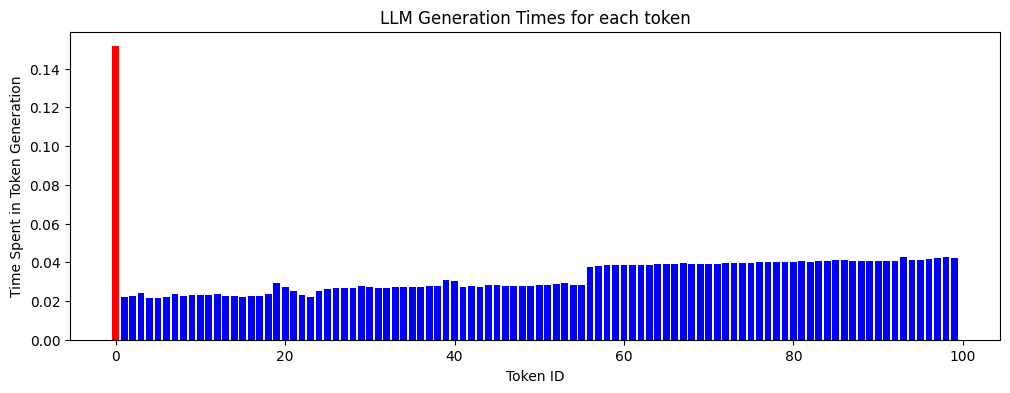

In [17]:
import matplotlib.pyplot as plt

# First chart: First bar red, others blue
plt.figure(figsize=(12, 4))
# plt.subplot(1, 2, 1)
plt.bar(range(len(times)), times, color=['red'] + ['blue'] * (len(times) - 1))
plt.xlabel("Token ID")
plt.ylabel("Time Spent in Token Generation")
plt.title("LLM Generation Times for each token")

# # Second chart: Exclude the first element
# plt.subplot(1, 2, 2)
# plt.bar(range(len(times) - 1), times[1:])
# plt.xlabel("Token ID")
# plt.ylabel("Time Spent in Token Generation")
# plt.title("Token Generation Times (Excluded the initial prompt tokens)")

# plt.tight_layout()
# plt.show()